# Exploration des données

**Objectif :** 
- But : comprendre le jeu de données avant le nettoyage et la transformation

Pour ca, on va étudier plusieurs catégorie :
1. la qualité générale du dataset 
2. les préférences musicales
3. La géographie
4. les différences de style musical entre les régions


In [176]:
import pandas as pd
import os 
import numpy as np
import matplotlib.pyplot as plt

## Chargement et aperçu du jeu de données

On va examiner le fichier, les types de variables, les noms de colonnes et quelques lignes pour comprendre la structure du questionnaire

In [177]:
filepath = "../dataset/hadopi-2020-musique-data.ods"
#df = pd.read_excel(filepath)
df = pd.read_excel( filepath, engine="odf",na_values=["#NUL!"])

In [178]:
df

,SEXE,QSEXE,RAGE2,RAGE3,XRAGE,AGGLOIFOP2,REG,REG2,REG3,REG13,...,Q60_3,Q60_4,Q60_5,Q61_r1_c1,Q61_r2_c1,Q61_r3_c1,Q61_r4_c1,DISPQUAL,sys_block_set_1,poids
0,Une femme,FEMME,De65aPlus,PlusDe49ans,Femme35ansEtPlus,MoinsDe100000Habitants,UDA7,BUDA4,PROVINCE,LanguedicRoussillonMidiP,...,NaN,NaN,NaN,NaN,Entre 1 et 49,NaN,NaN,Long,"2,3,1",1.006791
1,Une femme,FEMME,De50a64ans1,PlusDe49ans,Femme35ansEtPlus,PlusDe100000Habitants,UDA6,BUDA3,PROVINCE,PaysDeLaLoire1,...,0,0,0,150 et plus,50 et plus,NaN,NaN,Long,"3,2,1",0.695394
2,Une femme,FEMME,De15a24ans,MoinsDe35ans,FemmeMoinsDe35ans,PlusDe100000Habitants,UDA2,BUDA2,PROVINCE,NordPasDeCalaisPicardie,...,L’offre légale est plus agréable à utiliser,0,0,Entre 50 et 99,NaN,Entre 50 et 99,NaN,Long,"1,3,2",0.659261
3,Une femme,FEMME,De35a49ans1,De35a49ans2,Femme35ansEtPlus,PlusDe100000Habitants,UDA9,BUDA5,PROVINCE,ProvenceAlpesCoteDAzur,...,NaN,NaN,NaN,Moins de 50,Entre 1 et 49,NaN,NaN,Long,"1,2,3",1.165641
4,Un homme,HOMME,De50a64ans1,PlusDe49ans,Homme35ansEtPlus,MoinsDe100000Habitants,UDA8,BUDA5,PROVINCE,AuvergneRhoneAlpes,...,0,0,0,Moins de 50,0,NaN,Moins de 20,Long,"2,1,3",1.819044
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2195,Une femme,FEMME,De35a49ans1,De35a49ans2,Femme35ansEtPlus,MoinsDe100000Habitants,UDA5,BUDA3,PROVINCE,Normandie,...,NaN,NaN,NaN,Moins de 50,Entre 1 et 49,NaN,NaN,Long,"1,2,3",2.557586
2196,Un homme,HOMME,De35a49ans1,De35a49ans2,Homme35ansEtPlus,MoinsDe100000Habitants,UDA8,BUDA5,PROVINCE,AuvergneRhoneAlpes,...,NaN,NaN,NaN,150 et plus,50 et plus,NaN,NaN,Long,"2,3,1",2.567871
2197,Une femme,FEMME,De35a49ans1,De35a49ans2,Femme35ansEtPlus,MoinsDe100000Habitants,UDA5,BUDA3,PROVINCE,Normandie,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Court,NaN,2.557586
2198,Une femme,FEMME,De35a49ans1,De35a49ans2,Femme35ansEtPlus,MoinsDe100000Habitants,UDA6,BUDA3,PROVINCE,PaysDeLaLoire1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Court,NaN,2.560643


In [179]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Columns: 261 entries, SEXE to poids
dtypes: float64(28), object(233)
memory usage: 4.4+ MB


In [180]:
df.shape

(2200, 261)

In [181]:
print(df.columns.tolist())

['SEXE', 'QSEXE', 'RAGE2', 'RAGE3', 'XRAGE', 'AGGLOIFOP2', 'REG', 'REG2', 'REG3', 'REG13', 'REG13C', 'PI4', 'STATUT', 'PCF4', 'FOYER', 'ENF', 'RS1', 'QRS1', 'Q1_1', 'Q1_2', 'Q1_3', 'Q1_4', 'Q1_5', 'Q1_6', 'Q1_7', 'Q1_8', 'Q1_9', 'Q1_10', 'Q1_11', 'Q2_r1', 'Q2_r2', 'Q2_r3', 'Q2_r4', 'Q2_r5', 'Q2_r6', 'Q2_r7', 'Q2_r8', 'Q2_r9', 'Q2_r10', 'Q2_r11', 'Q3', 'Q4', 'Q5_1', 'Q5_2', 'Q5_3', 'Q5_4', 'Q5_5', 'Q5_6', 'Q5_7', 'Q5_8', 'Q5_9', 'Q5_10', 'Q5_11', 'Q5_12', 'Q5_13', 'Q6_r1', 'Q6_r2', 'Q6_r3', 'Q6_r4', 'Q6_r5', 'Q6_r6', 'Q6_r7', 'Q7', 'Q7bis', 'Q8_1', 'Q8_2', 'Q8_3', 'Q8_4', 'Q8_5', 'Q8_6', 'Q16_1', 'Q16_2', 'Q16_3', 'Q16_4', 'Q16_5', 'Q16_6', 'Q16_7', 'Q16_8', 'Q16_9', 'Q16_10', 'Q16_11', 'Q16_12', 'Q17', 'Q18_1', 'Q18_2', 'Q18_3', 'Q18_4', 'Q18_5', 'Q18_6', 'Q18_7', 'Q18_8', 'Q18_9', 'Q19_r1', 'Q19_r2', 'Q20_r1', 'Q20_r2', 'Q20_r3', 'Q20_r4', 'Q20_r5', 'Q21_r1', 'Q21_r2', 'Q21_r3', 'Q21_r4', 'ALEA', 'Q22ALEA1', 'Q22ALEA2', 'Q23_r1', 'Q23_r2', 'Q24_1', 'Q24_2', 'Q24_3', 'Q24_4', 'Q24_5', 

In [182]:
df.head(5)

,SEXE,QSEXE,RAGE2,RAGE3,XRAGE,AGGLOIFOP2,REG,REG2,REG3,REG13,...,Q60_3,Q60_4,Q60_5,Q61_r1_c1,Q61_r2_c1,Q61_r3_c1,Q61_r4_c1,DISPQUAL,sys_block_set_1,poids
0,Une femme,FEMME,De65aPlus,PlusDe49ans,Femme35ansEtPlus,MoinsDe100000Habitants,UDA7,BUDA4,PROVINCE,LanguedicRoussillonMidiP,...,NaN,NaN,NaN,NaN,Entre 1 et 49,NaN,NaN,Long,"2,3,1",1.006791
1,Une femme,FEMME,De50a64ans1,PlusDe49ans,Femme35ansEtPlus,PlusDe100000Habitants,UDA6,BUDA3,PROVINCE,PaysDeLaLoire1,...,0,0,0,150 et plus,50 et plus,NaN,NaN,Long,"3,2,1",0.695394
2,Une femme,FEMME,De15a24ans,MoinsDe35ans,FemmeMoinsDe35ans,PlusDe100000Habitants,UDA2,BUDA2,PROVINCE,NordPasDeCalaisPicardie,...,L’offre légale est plus agréable à utiliser,0,0,Entre 50 et 99,NaN,Entre 50 et 99,NaN,Long,"1,3,2",0.659261
3,Une femme,FEMME,De35a49ans1,De35a49ans2,Femme35ansEtPlus,PlusDe100000Habitants,UDA9,BUDA5,PROVINCE,ProvenceAlpesCoteDAzur,...,NaN,NaN,NaN,Moins de 50,Entre 1 et 49,NaN,NaN,Long,"1,2,3",1.165641
4,Un homme,HOMME,De50a64ans1,PlusDe49ans,Homme35ansEtPlus,MoinsDe100000Habitants,UDA8,BUDA5,PROVINCE,AuvergneRhoneAlpes,...,0,0,0,Moins de 50,0,NaN,Moins de 20,Long,"2,1,3",1.819044


## La qualité des données
### Valeurs manquantes 

- On regarde quelles colonnes contiennent des valeurs manquantes
- On calcule le pourcentage de valeurs manquantes par colonne
- On repère les colonnes complètement vides

In [183]:
# Nettoyer les espaces et les codes d’absence sans transformer les zéros.
for col in df.select_dtypes(include=['object', 'string']).columns:
    df[col] = df[col].map(lambda x: x.strip() if isinstance(x, str) else x)
    df[col] = df[col].map(
        lambda x: np.nan if isinstance(x, str) and x in {'#NUL!', ''} else x)

audit = pd.DataFrame({
    'Absences (n)': df.isna().sum(),
    'Absences (%)': (100 * df.isna().mean()).round(1),
    'Modalités renseignées': df.nunique(dropna=True)
})
display(audit.sort_values('Absences (%)', ascending=False).head(15))
print('Colonnes entièrement vides :', audit.index[audit['Absences (%)'].eq(100)].tolist())


,Absences (n),Absences (%),Modalités renseignées
Q2_r10,2200,100.0,0
Q2_r11,2200,100.0,0
Q25_10,2187,99.4,2
Q25_8,2028,92.2,2
Q55_6,2020,91.8,2
Q55_8,2020,91.8,2
Q55_7,2020,91.8,2
Q55_5,2020,91.8,2
Q55_1,2020,91.8,2
Q55_2,2020,91.8,2


Colonnes entièrement vides : ['Q2_r10', 'Q2_r11']


### Lignes identiques

- On vérifie s'il y a des lignes identiques
Il faut savoir que deux lignes identiques ne sont pas forcement la même personne, c'est pour ca qu'on doit regarder toutes les données 

In [184]:
# lignes concernées (premières apparitions comprises)
print("Personnes identiques :", df.duplicated(keep=False).sum())

# Lignes à supprimer (premières apparitions non comprises)
print("Doublons à supprimer :", df.duplicated().sum())
df[df.duplicated()]

Personnes identiques : 12
Doublons à supprimer : 6


,SEXE,QSEXE,RAGE2,RAGE3,XRAGE,AGGLOIFOP2,REG,REG2,REG3,REG13,...,Q60_3,Q60_4,Q60_5,Q61_r1_c1,Q61_r2_c1,Q61_r3_c1,Q61_r4_c1,DISPQUAL,sys_block_set_1,poids
710,Un homme,HOMME,De65aPlus,PlusDe49ans,Homme35ansEtPlus,MoinsDe100000Habitants,UDA8,BUDA5,PROVINCE,AuvergneRhoneAlpes,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Court,NaN,0.736057
712,Un homme,HOMME,De65aPlus,PlusDe49ans,Homme35ansEtPlus,PlusDe100000Habitants,UDA8,BUDA5,PROVINCE,AuvergneRhoneAlpes,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Court,NaN,0.765518
1044,Un homme,HOMME,De65aPlus,PlusDe49ans,Homme35ansEtPlus,MoinsDe100000Habitants,UDA8,BUDA5,PROVINCE,AuvergneRhoneAlpes,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Court,NaN,0.736057
1063,Un homme,HOMME,De65aPlus,PlusDe49ans,Homme35ansEtPlus,MoinsDe100000Habitants,UDA6,BUDA3,PROVINCE,Bretagne1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Court,NaN,0.732905
1106,Une femme,FEMME,De65aPlus,PlusDe49ans,Femme35ansEtPlus,PlusDe100000Habitants,UDA9,BUDA5,PROVINCE,ProvenceAlpesCoteDAzur,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Court,NaN,1.804310
2014,Un homme,HOMME,De35a49ans1,De35a49ans2,Homme35ansEtPlus,PlusDe100000Habitants,UDA1,BUDA1,RegionIleDeFrance,IleDeFrance1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Court,NaN,0.882059


### variables peu renseignées

On regarde les différentes valeurs des colonnes avec beaucoup de données manquantes
et on doit vérifier si ce sont bien des valeurs manquantes


In [185]:
colonnes_80 = audit[audit["Absences (%)"] >= 80]
valeurs = pd.DataFrame({
    "Valeurs distinctes": [
        df[colonne].dropna().unique().tolist()
        for colonne in colonnes_80.index
    ]
}, index=colonnes_80.index)

with pd.option_context("display.max_rows", None,
                       "display.max_colwidth", None):
    display(valeurs)

,Valeurs distinctes
Q2_r9,"[Uniquement de façon légale, Généralement de façon légale même s’il peut m’arriver de le faire de manière illégale, Autant de manière légale qu’illégale, Généralement de façon illégale même s’il peut m’arriver de le faire de manière légale, Uniquement de manière illégale]"
Q2_r10,[]
Q2_r11,[]
Q24_3,"[Les réseaux sociaux (Instagram, Facebook, Snapchat…), 0]"
Q25_1,"[Des services ou des applications de streaming musical (Spotify, Deezer, Apple Music, Soundcloud, Napster…), 0]"
Q25_2,"[0, Des plateformes de partage de vidéos (YouTube, Dailymotion, Tik Tok…)]"
Q25_3,"[Les réseaux sociaux (Instagram, Facebook, Snapchat…), 0]"
Q25_4,"[Des sites ou applications de radio musicales traditionnelles (Fun radio, Radio Classique, RTL2, …) ou uniquement diffu, 0]"
Q25_5,"[Les concerts / festivals, 0]"
Q25_6,"[0, Les chaînes de télévision musicales]"


## Préférences musicales

### Genres présents dans le questionnaire

- Q5_1 à Q5_13 = les 13 genres musicaux

On regarde à quels genres correspondent ces colonnes


In [186]:
genres = [f"Q5_{i}" for i in range(1, 14)]

for colonne in genres:
    valeurs = df[colonne].dropna()
    styles = valeurs[valeurs.astype(str) != "0"].unique()

    print(f"{colonne} : {', '.join(styles)}")

Q5_1 : Variété Française
Q5_2 : Pop / Rock
Q5_3 : Rap / Hip-Hop
Q5_4 : Classique
Q5_5 : Jazz
Q5_6 : Dance
Q5_7 : Electronique
Q5_8 : Métal
Q5_9 : R&B
Q5_10 : Soul
Q5_11 : Reggae
Q5_12 : Musiques du monde
Q5_13 : Autres genres


### Fréquence des style de musique 

- On calcule le pourcentage de personnes qui aiment chaque genre musical
- et on repère les genres les plus et les moins populaires

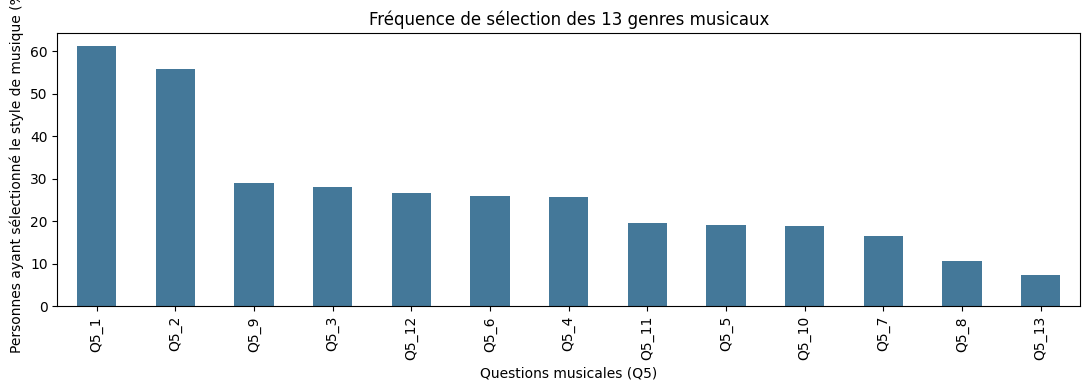

In [187]:

# Les 13 genres musicaux
style = [f"Q5_{i}" for i in range(1, 14)]

# Pourcentage de personnes ayant sélectionné chaque genre
frequences_genres = pd.Series({
    colonne: (df[colonne].dropna().astype(str).str.strip() != "0").mean() * 100
    for colonne in style
}).sort_values(ascending=False)

ax = frequences_genres.plot.bar(figsize=(11, 4), color="#447899")
ax.set_ylabel("Personnes ayant sélectionné le style de musique (%)")
ax.set_xlabel("Questions musicales (Q5)")
ax.set_title("Fréquence de sélection des 13 genres musicaux")

plt.tight_layout()
plt.show()


## Exploration géographique
### Variables géographiques 

- Le dataset contient plusieurs représentations de la localisation
Cest pour ca qu'on les compare pour choisir une cible la plus adaptée 


In [188]:
geographie = ["REG", "REG2", "REG3", "REG13", "REG13C"]

for colonne in geographie:
    print(f"\n--- {colonne} ---")
    display(df[colonne].value_counts(dropna=False))


--- REG ---


REG
UDA1    441
UDA6    292
UDA8    271
UDA7    266
UDA9    223
UDA3    199
UDA5    187
UDA4    183
UDA2    138
Name: count, dtype: int64


--- REG2 ---


REG2
BUDA2    520
BUDA5    494
BUDA3    479
BUDA1    441
BUDA4    266
Name: count, dtype: int64


--- REG3 ---


REG3
PROVINCE             1759
RegionIleDeFrance     441
Name: count, dtype: int64


--- REG13 ---


REG13
IleDeFrance1                441
AuvergneRhoneAlpes          271
AlsaceChampagneArdenneLo    220
AquitaineLimousinPoitouC    210
NordPasDeCalaisPicardie     205
LanguedicRoussillonMidiP    178
ProvenceAlpesCoteDAzur      143
PaysDeLaLoire1              139
Bretagne1                   111
Normandie                   102
BourgogneFrancheComte        95
CentreValDeLoire             85
Name: count, dtype: int64


--- REG13C ---


REG13C
IleDeFrance2              441
AuvergneRhoneAlpes1       271
AlsaceChampagneArdenn1    220
AquitaineLimousinPoit1    210
NordPasDeCalaisPicard1    205
LanguedicRoussillonMi1    178
PACACorse                 143
PaysDeLaLoire2            139
Bretagne2                 111
Normandie1                102
BourgogneFrancheComte1     95
CentreValDeLoire1          85
Name: count, dtype: int64

### Choix de la variable cible

Le dataset contient plusieurs variables géographiques :
- REG : 9 zones
- REG2 : 5 zones
- REG3 : Île-de-France / Province
- REG13 et REG13C : régions
- AGGLOIFOP2 : taille de l'agglomération


On choisit REG13 et REG13C :
- Plus précis que REG2 et REG3
- Permet de prédire directement la région

Attention :
- On ne garde pas les autres variables géographiques pour la prédiction
Sinon, le modèle aurait déjà des informations sur la région → fuite de données

Par contre on compare les deux pour voir la différence

### Correspondance entre REG13 et REG13C
Region identique, on garde seulement REG13 pour la suite


In [189]:
display(df[["REG13", "REG13C"]].drop_duplicates())

,REG13,REG13C
0,LanguedicRoussillonMidiP,LanguedicRoussillonMi1
1,PaysDeLaLoire1,PaysDeLaLoire2
2,NordPasDeCalaisPicardie,NordPasDeCalaisPicard1
3,ProvenceAlpesCoteDAzur,PACACorse
4,AuvergneRhoneAlpes,AuvergneRhoneAlpes1
6,AlsaceChampagneArdenneLo,AlsaceChampagneArdenn1
7,CentreValDeLoire,CentreValDeLoire1
8,AquitaineLimousinPoitouC,AquitaineLimousinPoit1
14,IleDeFrance1,IleDeFrance2
20,Bretagne1,Bretagne2


### Effectifs et proportions des régions

- On regarde le nombre de personnes par région
car certaines régions ont plus de personnes que d'autres

=> Ce qui peut influencer les résultats du modèle

- On doit comparer notre modèle à une prédiction qui choisit toujours la région la plus représentée

On le remarque avec le graphique qui montre que c'est déséquilibré entre les régions 

,Effectif,Pourcentage (%)
REG13,,
IleDeFrance1,441,20.0
AuvergneRhoneAlpes,271,12.3
AlsaceChampagneArdenneLo,220,10.0
AquitaineLimousinPoitouC,210,9.5
NordPasDeCalaisPicardie,205,9.3
LanguedicRoussillonMidiP,178,8.1
ProvenceAlpesCoteDAzur,143,6.5
PaysDeLaLoire1,139,6.3
Bretagne1,111,5.0


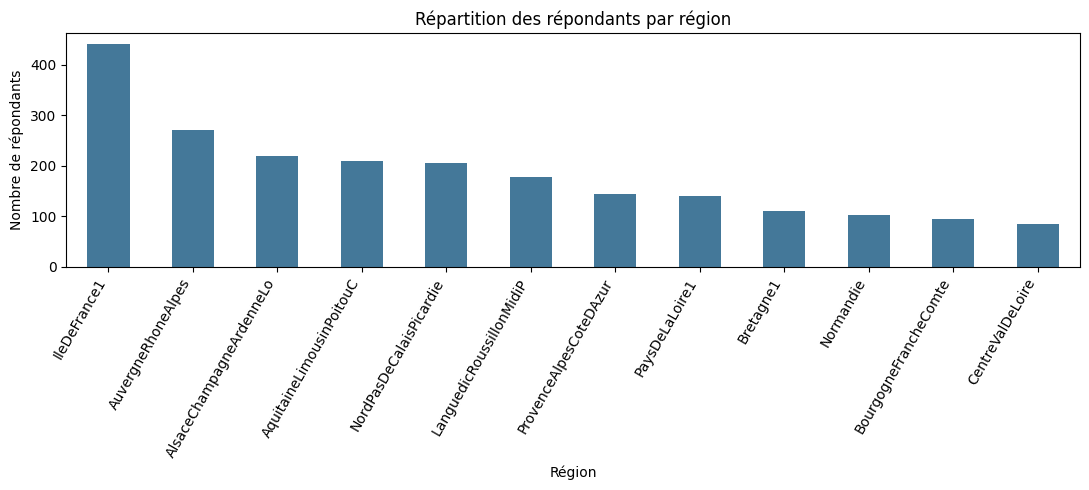

In [190]:
regions = pd.DataFrame({
    "Effectif": df["REG13"].value_counts(),
    "Pourcentage (%)": (
        df["REG13"].value_counts(normalize=True) * 100
    ).round(1)
})

display(regions)
# Graphique de la répartition des régions
ax = regions["Effectif"].sort_values(ascending=False).plot.bar(figsize=(11, 5), color="#447899")
ax.set_title("Répartition des répondants par région")
ax.set_xlabel("Région")
ax.set_ylabel("Nombre de répondants")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()


### Pourcentage de chaque genre par région

- On calcule le pourcentage de personnes qui aiment chaque genre musical par région
Et on ne prend pas en compte les lignes avec des valeurs manquantes

In [191]:
genres = [f"Q5_{i}" for i in range(1, 14)]

exploration = df[genres + ["REG13"]].dropna().copy()
noms_genres = {}

for colonne in genres:
    reponses = exploration[colonne].astype("string").str.strip()

    # Retrouver le nom du genre
    noms_genres[colonne] = reponses[reponses != "0"].iloc[0]

    # 1 = genre sélectionné, 0 = non sélectionné
    exploration[colonne] = (reponses != "0").astype(int)

pourcentages = (
    exploration.groupby("REG13")[genres]
    .mean()
    .mul(100)
    .rename(columns=noms_genres)
    .round(1)
)

In [192]:
#pourcentage de personnes ayant sélectionné chaque genre dans chaque région
display(pourcentages)

,Variété Française,Pop / Rock,Rap / Hip-Hop,Classique,Jazz,Dance,Electronique,Métal,R&B,Soul,Reggae,Musiques du monde,Autres genres
REG13,,,,,,,,,,,,,
AlsaceChampagneArdenneLo,63.5,58.0,30.0,27.0,18.0,25.5,20.5,16.5,29.0,18.5,14.5,27.0,8.0
AquitaineLimousinPoitouC,65.5,58.8,24.7,28.9,21.1,28.4,18.6,9.8,26.3,17.0,20.1,30.4,10.3
AuvergneRhoneAlpes,58.2,57.0,23.2,20.3,17.7,24.1,21.9,10.1,28.3,21.5,19.4,21.9,3.8
BourgogneFrancheComte,73.8,56.0,25.0,20.2,9.5,42.9,20.2,9.5,31.0,15.5,22.6,23.8,16.7
Bretagne1,63.9,59.8,21.6,21.6,18.6,20.6,17.5,13.4,20.6,17.5,23.7,29.9,9.3
CentreValDeLoire,62.8,55.1,28.2,28.2,16.7,34.6,17.9,11.5,30.8,17.9,21.8,25.6,10.3
IleDeFrance1,51.7,52.0,31.9,32.7,21.0,19.8,12.6,11.1,31.9,18.6,19.6,27.7,6.7
LanguedicRoussillonMidiP,66.5,60.9,24.8,26.7,22.4,27.3,14.9,11.2,26.1,21.1,19.3,26.1,3.7
NordPasDeCalaisPicardie,67.0,48.9,31.4,17.0,11.2,30.9,14.4,7.4,29.3,17.0,14.9,27.1,8.5


### Carte de chaleur des préférences régionales

Chaque case correspond au pourcentage de personnes de la région ayant sélectionné le style de musique
**Conclusion :**
- On peut voir quelques différences entre les régions
- Mais les goûts musicaux restent assez proches
- On verra avec le modèle si ces différences suffisent pour prédire la région


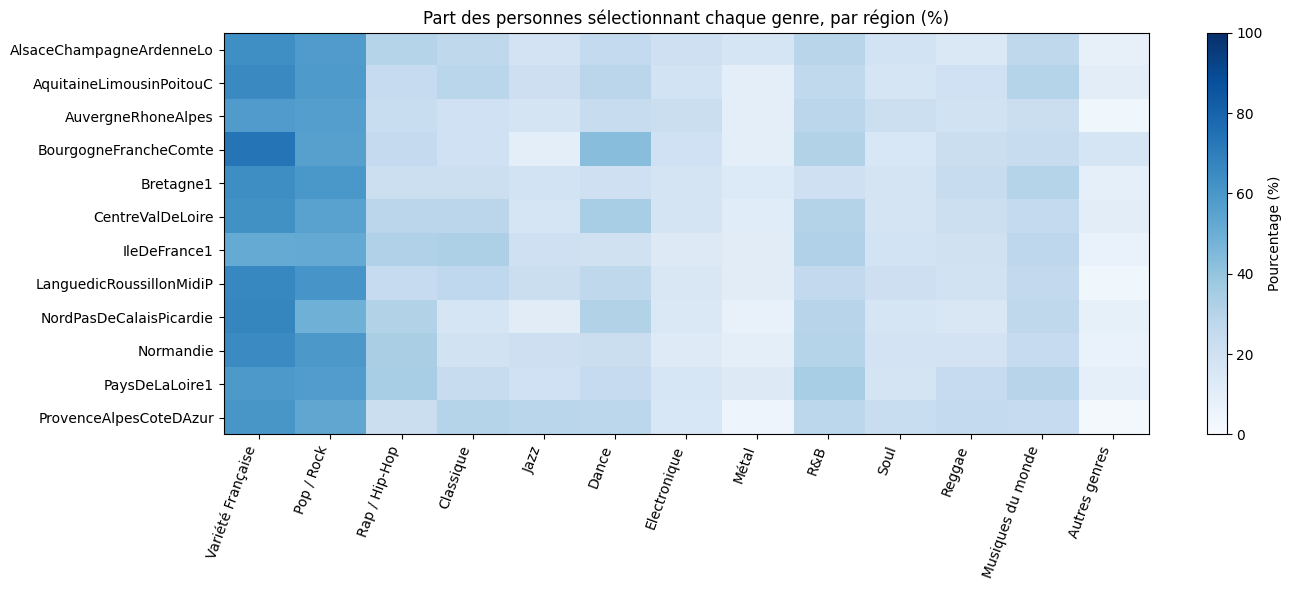

In [193]:
fig, ax = plt.subplots(figsize=(14, 6))
image = ax.imshow(pourcentages.to_numpy(), aspect="auto", cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(len(pourcentages.columns)), pourcentages.columns, rotation=70, ha="right")
ax.set_yticks(range(len(pourcentages.index)), pourcentages.index)
ax.set_title("Part des personnes sélectionnant chaque genre, par région (%)")
fig.colorbar(image, ax=ax, label="Pourcentage (%)")
plt.tight_layout()
plt.show()

## Analyse des personnes et des non-réponses

### Personnes sans réponse sur les 13 genres musicaux

Ce tableau croise les absences de réponses avec `Q3` pour comprendre les origines

In [194]:
sans_genres = df[genres].isna().all(axis=1)

display(pd.crosstab(
    df["Q3"],
    sans_genres,
    colnames=["Tous les genres manquants"]
))

Tous les genres manquants,False,True
Q3,,
1 à 3 fois par mois,222,0
1 à 5 fois par semaine,480,0
Jamais,0,214
Moins souvent,188,0
Plusieurs fois par jour,548,0
Tous les jours ou presque,548,0


Les 214 personnes qui n’écoutent jamais de musique vont être retirées du dataset dans la partie nettoyage

## Bilan

- **Données :** on a identifié des valeurs manquantes et des doublons
- **Personnes :** on a analysé les réponses aux questionnaires
- **Régions :** on a vu la répartition des personnes selon les régions
- **Musique :** comparaison des préférences musicales entre les régions